# Gasífera ML: Churn y Forecasting

Proyecto de ML sobre los datos sintéticos de Gasífera del Valle S.A. (ene-2024 a nov-2026), usando las tablas gold del pipeline.

**Fase 1 — Churn**: predecir la probabilidad de baja por cliente (`gold_clientes_360`, 18.000 clientes, 896 bajas ≈ 5%). Modelos: Logistic Regression vs Random Forest (Spark MLlib), con `weightCol` para el desbalance. Entregables: métricas AUC-ROC/AUC-PR, lift del decil superior, importancias y top-20 clientes activos en riesgo.

**Fase 2 — Forecasting**: proyección mensual de demanda (6 meses) con baseline estacional naive vs regresión con lags/calendario, validación temporal honesta (train hasta jun-2026, validación jul–nov-2026).

**Nota de integridad**: se detectó filtración de target y se excluyó. Los clientes de baja tienen volumen/facturación/impago en 0 *porque la baja los causa* — esas columnas son consecuencia del target y no se usan como features.

In [0]:
# Carga y EDA inicial de churn
from pyspark.sql import functions as F

clientes = spark.read.table("workspace.gasifera_gold.gold_clientes_360")
print("Filas:", clientes.count(), "| Columnas:", len(clientes.columns))

print("\n=== Balance del target (estado) ===")
clientes.groupBy("estado").count().orderBy("estado").show()

print("=== Estadística descriptiva por estado ===")
NUM_EDA = ["antiguedad_meses", "tickets", "pct_sla", "satisfaccion_media", "volumen_total_m3", "facturacion_total_usd"]
display(clientes.groupBy("estado").agg(
    F.count("*").alias("n"),
    *[F.round(F.avg(c), 2).alias(c) for c in NUM_EDA]
).orderBy("estado"))

print("=== Tipos de feature ===")
for c, t in [("tipo_cliente", "categorico"), ("region", "categorico"),
             ("antiguedad_meses", "numerico"), ("tickets", "numerico"),
             ("pct_sla", "numerico"), ("satisfaccion_media", "numerico"),
             ("volumen_total_m3", "numerico (EXCLUIDO: filtracion)"),
             ("facturacion_total_usd", "numerico (EXCLUIDO: filtracion)"),
             ("tuvo_impago", "binario (EXCLUIDO: filtracion)")]:
    print(f"  {c}: {t}")

Filas: 18000 | Columnas: 14

=== Balance del target (estado) ===
+----------+-----+
|    estado|count|
+----------+-----+
|    activo|16202|
|      baja|  896|
|suspendido|  902|
+----------+-----+

=== Estadística descriptiva por estado ===


estado,n,antiguedad_meses,tickets,pct_sla,satisfaccion_media,volumen_total_m3,facturacion_total_usd
activo,16202,223.59,3.33,96.49,3.76,248658.76,100607.23
baja,896,226.7,3.32,96.39,3.77,0.0,0.0
suspendido,902,227.55,3.38,96.41,3.78,261993.14,105350.37


=== Tipos de feature ===
  tipo_cliente: categorico
  region: categorico
  antiguedad_meses: numerico
  tickets: numerico
  pct_sla: numerico
  satisfaccion_media: numerico
  volumen_total_m3: numerico (EXCLUIDO: filtracion)
  facturacion_total_usd: numerico (EXCLUIDO: filtracion)
  tuvo_impago: binario (EXCLUIDO: filtracion)


## Fase 1 — Churn: decisiones de modelado

* **Target**: `es_baja` = (estado == 'baja'). Clase minoritaria ≈ **5%** → split estratificado + `weightCol` (peso de la clase positiva = ratio neg/pos ≈ 19).
* **Features sin filtración**: `tipo_cliente`, `region`, `antiguedad_meses`, `tickets`, `pct_sla`, `satisfaccion_media`. Se excluyen las agregadas de consumo/facturación (consecuencia de la baja).
* **Split**: estratificado 80/20 con `sampleBy` (semilla 42); test = anti-join, garantiza clientes disjuntos.
* **Modelos**: Logistic Regression (baseline lineal) y Random Forest (200 árboles, profundidad 6), ambos con `weightCol`.
* **Métrica de selección**: AUC-PR (más informativa que AUC-ROC con 5% de positivos); se reporta además lift del decil superior.

In [0]:
# Preprocesamiento y split estratificado
from pyspark.ml import Pipeline
from pyspark.ml.feature import StringIndexer, OneHotEncoder, VectorAssembler
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier

CAT = ["tipo_cliente", "region"]
NUM = ["antiguedad_meses", "tickets", "pct_sla", "satisfaccion_media"]
RAW = CAT + NUM

df = clientes.withColumn("es_baja", F.when(F.col("estado") == "baja", 1.0).otherwise(0.0))

n_pos = df.filter("es_baja = 1").count()
n_neg = df.filter("es_baja = 0").count()
w_pos = n_neg / n_pos
df = df.withColumn("peso", F.when(F.col("es_baja") == 1.0, w_pos).otherwise(1.0))
print(f"Positivos: {n_pos} | Negativos: {n_neg} | peso clase positiva: {w_pos:.2f}")

train = df.sampleBy("es_baja", {0.0: 0.8, 1.0: 0.8}, seed=42)
test = df.join(train.select("cliente_id"), "cliente_id", "left_anti")
print(f"train: {train.count()} filas ({train.filter('es_baja=1').count()} bajas) | test: {test.count()} filas ({test.filter('es_baja=1').count()} bajas)")

indexers = [StringIndexer(inputCol=c, outputCol=f"{c}_idx", handleInvalid="keep") for c in CAT]
encoder = OneHotEncoder(inputCols=[f"{c}_idx" for c in CAT], outputCols=[f"{c}_ohe" for c in CAT])
assembler = VectorAssembler(inputCols=[f"{c}_ohe" for c in CAT] + NUM, outputCol="features")

lr = LogisticRegression(labelCol="es_baja", weightCol="peso", maxIter=100)
rf = RandomForestClassifier(labelCol="es_baja", weightCol="peso", numTrees=200, maxDepth=6, seed=42)

pipe_lr = Pipeline(stages=indexers + [encoder, assembler, lr])
pipe_rf = Pipeline(stages=indexers + [encoder, assembler, rf])
print("Pipelines listos (preprocesamiento dentro del modelo: sin skew train/serve)")

Positivos: 896 | Negativos: 17104 | peso clase positiva: 19.09
train: 14458 filas (701 bajas) | test: 3542 filas (195 bajas)
Pipelines listos (preprocesamiento dentro del modelo: sin skew train/serve)


In [0]:
# Entrenamiento y evaluación: LR vs RF
from pyspark.ml.evaluation import BinaryClassificationEvaluator
import pandas as pd

EVAL_AUC = BinaryClassificationEvaluator(labelCol="es_baja", metricName="areaUnderROC")
EVAL_PR = BinaryClassificationEvaluator(labelCol="es_baja", metricName="areaUnderPR")

def evaluar(pipeline, nombre):
    modelo = pipeline.fit(train)
    pred = modelo.transform(test)
    auc = EVAL_AUC.evaluate(pred)
    pr = EVAL_PR.evaluate(pred)
    pdf = pred.select("es_baja", "probability").toPandas()
    pdf["prob"] = pdf["probability"].apply(lambda p: float(p[1]))
    tp = ((pdf.prob >= 0.5) & (pdf.es_baja == 1)).sum()
    fp = ((pdf.prob >= 0.5) & (pdf.es_baja == 0)).sum()
    fn = ((pdf.prob < 0.5) & (pdf.es_baja == 1)).sum()
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)
    pdf = pdf.sort_values("prob", ascending=False).reset_index(drop=True)
    top = pdf.head(len(pdf) // 10)
    lift = top.es_baja.mean() / pdf.es_baja.mean()
    print(f"{nombre}: AUC-ROC={auc:.3f} | AUC-PR={pr:.3f} | precision@0.5={precision:.3f} | recall@0.5={recall:.3f} | lift top-decil={lift:.2f}x")
    return {"nombre": nombre, "auc": auc, "pr": pr, "lift": lift, "modelo": modelo}

res_lr = evaluar(pipe_lr, "Logistic Regression")
res_rf = evaluar(pipe_rf, "Random Forest")

mejor = max([res_lr, res_rf], key=lambda r: r["pr"])
base_pr = test.filter("es_baja = 1").count() / test.count()
print(f"\n>>> Mejor modelo por AUC-PR: {mejor['nombre']}")
print(f">>> Baseline aleatorio AUC-PR = {base_pr:.3f}")

Logistic Regression: AUC-ROC=0.486 | AUC-PR=0.053 | precision@0.5=0.052 | recall@0.5=0.467 | lift top-decil=0.87x
Random Forest: AUC-ROC=0.502 | AUC-PR=0.054 | precision@0.5=0.058 | recall@0.5=0.262 | lift top-decil=0.77x

>>> Mejor modelo por AUC-PR: Random Forest
>>> Baseline aleatorio AUC-PR = 0.055


In [0]:
# Importancia de variables y top-20 clientes activos en riesgo
import builtins

mejor_pipe = mejor["modelo"]
nombres = []
for stage in mejor_pipe.stages:
    if hasattr(stage, "labels"):  # StringIndexerModel -> una fila por nivel de categoría (OHE)
        nombres += [f"{stage.getInputCol()}={l}" for l in stage.labels]
nombres += NUM

est_final = mejor_pipe.stages[-1]
if hasattr(est_final, "featureImportances"):
    imps = sorted(zip(nombres, est_final.featureImportances.toArray()), key=lambda t: -t[1])
    print(f"=== Importancias ({mejor['nombre']}) ===")
    for n, v in imps[:12]:
        print(f"  {n}: {v:.3f}")
else:
    coefs = est_final.coefficientArray if hasattr(est_final, "coefficientArray") else est_final.coefficients.toArray()
    imps = sorted(zip(nombres, builtins.abs(coefs)), key=lambda t: -t[1])
    print(f"=== |Coeficientes| ({mejor['nombre']}) ===")
    for n, v in imps[:12]:
        print(f"  {n}: {v:.4f}")

print("\n=== TOP-20 clientes ACTIVOS con mayor probabilidad de baja (campaña de retención) ===")
activos = spark.read.table("workspace.gasifera_gold.gold_clientes_360").filter("estado = 'activo'")
pdf_act = mejor_pipe.transform(activos).select("cliente_id", "tipo_cliente", "region", "probability").toPandas()
pdf_act["prob_baja"] = pdf_act["probability"].apply(lambda p: round(float(p[1]), 4))
display(pdf_act.drop(columns="probability").sort_values("prob_baja", ascending=False).head(20).reset_index(drop=True))

=== Importancias (Random Forest) ===
  antiguedad_meses: 0.255
  satisfaccion_media: 0.180
  tickets: 0.160
  pct_sla: 0.070
  region=Valle Sur: 0.038
  tipo_cliente=residencial: 0.035
  tipo_cliente=comercial: 0.035
  region=Valle Centro: 0.033
  region=Llanura Oeste: 0.029
  region=Sierra Alta: 0.028
  tipo_cliente=gnv: 0.023
  region=Costa Este: 0.022

=== TOP-20 clientes ACTIVOS con mayor probabilidad de baja (campaña de retención) ===


cliente_id,tipo_cliente,region,prob_baja
CLI016693,residencial,Delta,0.5629
CLI016032,residencial,Delta,0.5627
CLI015119,residencial,Delta,0.5603
CLI016912,residencial,Delta,0.5569
CLI012655,residencial,Delta,0.5569
CLI005856,residencial,Costa Este,0.5542
CLI004540,residencial,Costa Este,0.5532
CLI013141,residencial,Costa Este,0.5524
CLI006664,residencial,Llanura Oeste,0.5523
CLI008786,residencial,Llanura Oeste,0.5523


In [0]:
# MLflow: tracking y logging del mejor pipeline de churn
import mlflow

try:
    mlflow.set_experiment("/Users/jlzarmas@gmail.com/gasifera_pipeline_calidad_y_gold_2d0da38e/mlflow-gasifera")
except Exception as e:
    print("Usando experimento por defecto:", e)

with mlflow.start_run(run_name="churn_gasifera") as run:
    mlflow.log_params({"modelo": mejor["nombre"], "n_train": train.count(), "n_test": test.count(),
                        "peso_clase_positiva": round(w_pos, 2), "seed": 42})
    mlflow.log_metrics({"auc_roc": mejor["auc"], "auc_pr": mejor["pr"], "lift_top_decil": mejor["lift"]})
    ejemplo = train.select(*RAW).limit(5).toPandas()
    ejemplo["pct_sla"] = ejemplo["pct_sla"].astype(float)  # Decimal no es JSON-serializable para el signature
    # En serverless, el logging de modelos SparkML exige una ruta UC como almacenamiento temporal
    mlflow.spark.log_model(mejor_pipe, "churn_model", dfs_tmpdir="/Volumes/workspace/gasifera/ml_models", input_example=ejemplo)
    print("Run MLflow:", run.info.run_id)
    print("Model URI:", mlflow.get_artifact_uri())

/databricks/python/lib/python3.12/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
2026/11/21 01:05:35 WARNING mlflow.utils.environment: Encountered an unexpected error while inferring pip requirements (model URI: /local_disk0/user_tmp_data/spark-373d68c7-a2c3-48e7-ba03-79/tmpr466dw1s/model, flavor: spark). Fall back to r

Run MLflow: f415639e264b48abb4b07801b4159434
Model URI: dbfs:/databricks/mlflow-tracking/681477608067172/f415639e264b48abb4b07801b4159434/artifacts


## Fase 2 — Forecasting de demanda mensual

* **Serie**: volumen mensual total desde `gold_consumo_mensual` (35 meses, ene-2024 a nov-2026).
* **Split temporal honesto**: train hasta jun-2026, validación jul–nov-2026 (los últimos 5 meses NUNCA en train). El timestamp es tiempo real de observación → holdout posterior refleja predecir el futuro.
* **Modelos**: baseline estacional naive (mismo mes del año anterior) vs regresión lineal con lag-12 + estacionalidad (sin/cos del mes) + tendencia. Solo lags ≥ horizonte (6) para predecir 6 meses sin recursión.
* **Métricas**: MAPE, RMSE y MASE (vs naive). Luego refit con todo el historial y proyección dic-2026 a may-2027 (total y por región).

Serie: 35 meses | 2024-01-01 -> 2026-11-01


periodo,volumen_m3
2024-01-01T00:00:00.000Z,1.174887197E8
2024-02-01T00:00:00.000Z,1.130189904E8
2024-03-01T00:00:00.000Z,1.1911473729999995E8
2024-04-01T00:00:00.000Z,1.1975941169999999E8
2024-05-01T00:00:00.000Z,1.2730296239999998E8


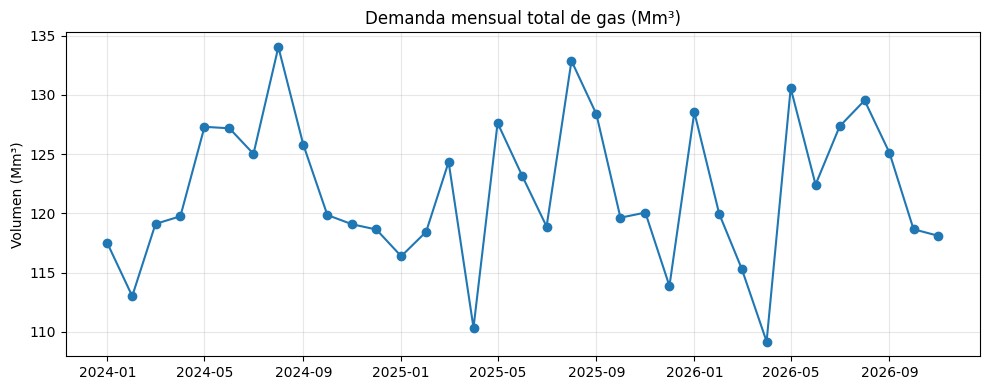

In [0]:
# Serie mensual y EDA temporal
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

serie = spark.sql("""
SELECT periodo, SUM(volumen_m3) AS volumen_m3
FROM workspace.gasifera_gold.gold_consumo_mensual
GROUP BY periodo ORDER BY periodo""").toPandas()
serie["periodo"] = pd.to_datetime(serie["periodo"])
serie = serie.sort_values("periodo").reset_index(drop=True)
print(f"Serie: {len(serie)} meses | {serie.periodo.min().date()} -> {serie.periodo.max().date()}")
display(serie.head())

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(serie.periodo, serie.volumen_m3 / 1e6, marker="o", color="#1f77b4")
ax.set_title("Demanda mensual total de gas (Mm³)")
ax.set_ylabel("Volumen (Mm³)")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

train: 18 meses | validación: 5 meses
Naive estacional : MAPE=2.86% | RMSE=4,429,646 m3 | MAE=3,599,704 m3
Regresión        : MAPE=3.47% | RMSE=5,129,880 m3 | MAE=4,304,093 m3
MASE (regresión vs naive) = 1.20  (<1 = mejor que naive)


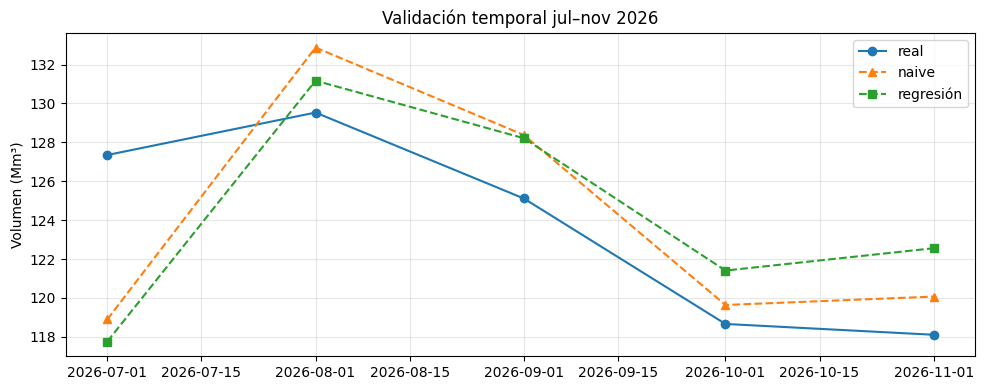

In [0]:
# Split temporal, baseline naive vs regresión, métricas
from sklearn.linear_model import LinearRegression

serie["lag_12"] = serie.volumen_m3.shift(12)
serie["mes"] = serie.periodo.dt.month
serie["sin_mes"] = np.sin(2 * np.pi * serie.mes / 12)
serie["cos_mes"] = np.cos(2 * np.pi * serie.mes / 12)
serie["tendencia"] = np.arange(len(serie))
FEATS = ["lag_12", "sin_mes", "cos_mes", "tendencia"]  # lag >= horizonte (6): sin recursión

train_f = serie[serie.periodo < "2026-07-01"].dropna(subset=FEATS)
val_f = serie[(serie.periodo >= "2026-07-01") & (serie.periodo < "2026-12-01")].copy()
print(f"train: {len(train_f)} meses | validación: {len(val_f)} meses")

val_f["pred_naive"] = val_f.lag_12  # estacional naive: mismo mes del año anterior
modelo = LinearRegression().fit(train_f[FEATS], train_f.volumen_m3)
val_f["pred_modelo"] = modelo.predict(val_f[FEATS])

mape = lambda y, p: float((abs(y - p) / y).mean() * 100)
rmse = lambda y, p: float(np.sqrt(((y - p) ** 2).mean()))
mae = lambda y, p: float(abs(y - p).mean())

m_naive = (mape(val_f.volumen_m3, val_f.pred_naive), rmse(val_f.volumen_m3, val_f.pred_naive), mae(val_f.volumen_m3, val_f.pred_naive))
m_model = (mape(val_f.volumen_m3, val_f.pred_modelo), rmse(val_f.volumen_m3, val_f.pred_modelo), mae(val_f.volumen_m3, val_f.pred_modelo))

print(f"Naive estacional : MAPE={m_naive[0]:.2f}% | RMSE={m_naive[1]:,.0f} m3 | MAE={m_naive[2]:,.0f} m3")
print(f"Regresión        : MAPE={m_model[0]:.2f}% | RMSE={m_model[1]:,.0f} m3 | MAE={m_model[2]:,.0f} m3")
print(f"MASE (regresión vs naive) = {m_model[2] / m_naive[2]:.2f}  (<1 = mejor que naive)")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(val_f.periodo, val_f.volumen_m3 / 1e6, marker="o", label="real")
ax.plot(val_f.periodo, val_f.pred_naive / 1e6, marker="^", linestyle="--", label="naive")
ax.plot(val_f.periodo, val_f.pred_modelo / 1e6, marker="s", linestyle="--", label="regresión")
ax.set_title("Validación temporal jul–nov 2026")
ax.set_ylabel("Volumen (Mm³)")
ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

=== Proyección TOTAL (Mm³) ===


periodo,pred_Mm3,real_12m_antes
2026-12-01T00:00:00.000Z,116.1,113.9
2027-01-01T00:00:00.000Z,125.4,128.5
2027-02-01T00:00:00.000Z,119.5,120.0
2027-03-01T00:00:00.000Z,116.3,115.3
2027-04-01T00:00:00.000Z,112.4,109.2
2027-05-01T00:00:00.000Z,127.0,130.6



=== Proyección 6 meses por región (Mm³) ===
region
Valle Norte      106.8
Valle Sur        102.1
Llanura Oeste     97.3
Delta             93.1
Altiplano         90.9
Costa Este        82.0
Valle Centro      76.8
Sierra Alta       75.2


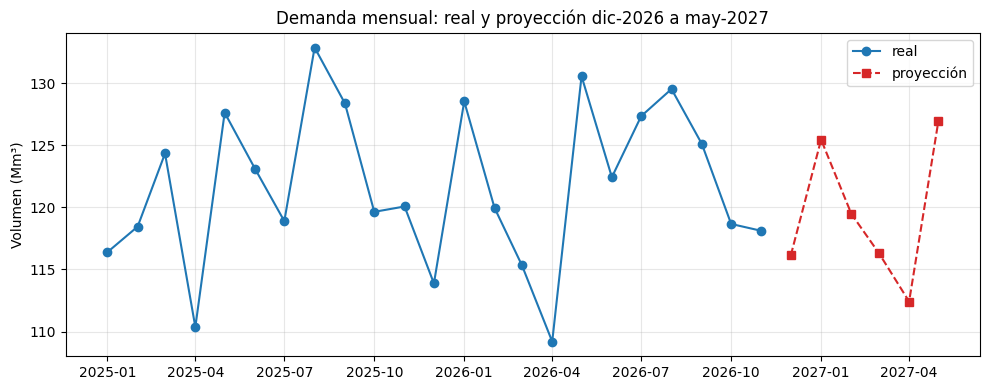

In [0]:
# Refit con todo el historial y proyección dic-2026 a may-2027 (total y por región)
serie_clean = serie.dropna(subset=FEATS)
modelo_full = LinearRegression().fit(serie_clean[FEATS], serie_clean.volumen_m3)

future_dates = pd.date_range(serie.periodo.max() + pd.offsets.MonthBegin(1), periods=6, freq="MS")
last_tend = serie.tendencia.iloc[-1]

rows = []
for i, p in enumerate(future_dates, start=1):
    lag12 = float(serie.loc[serie.periodo == p - pd.DateOffset(months=12), "volumen_m3"].iloc[0])
    rows.append({"periodo": p, "lag_12": lag12, "sin_mes": np.sin(2 * np.pi * p.month / 12),
                 "cos_mes": np.cos(2 * np.pi * p.month / 12), "tendencia": last_tend + i})
proj = pd.DataFrame(rows)
proj["pred"] = modelo_full.predict(proj[FEATS])

print("=== Proyección TOTAL (Mm³) ===")
proj_out = proj[["periodo", "pred"]].copy()
proj_out["pred_Mm3"] = (proj_out.pred / 1e6).round(1)
proj_out["real_12m_antes"] = (proj.lag_12 / 1e6).round(1)
display(proj_out[["periodo", "pred_Mm3", "real_12m_antes"]])

# Por región
reg = spark.sql("""
SELECT periodo, region, SUM(volumen_m3) AS volumen_m3
FROM workspace.gasifera_gold.gold_consumo_mensual GROUP BY periodo, region""").toPandas()
reg["periodo"] = pd.to_datetime(reg["periodo"])

proj_reg = []
for r, g in reg.groupby("region"):
    g = g.sort_values("periodo").reset_index(drop=True)
    g["lag_12"] = g.volumen_m3.shift(12)
    g["mes"] = g.periodo.dt.month
    g["sin_mes"] = np.sin(2 * np.pi * g.mes / 12)
    g["cos_mes"] = np.cos(2 * np.pi * g.mes / 12)
    g["tendencia"] = np.arange(len(g))
    tr = g[g.periodo < "2026-07-01"].dropna(subset=FEATS)
    if len(tr) < 12:
        continue
    mr = LinearRegression().fit(tr[FEATS], tr.volumen_m3)
    rows_r = []
    for i, p in enumerate(future_dates, start=1):
        lag12 = float(g.loc[g.periodo == p - pd.DateOffset(months=12), "volumen_m3"].iloc[0])
        rows_r.append({"region": r, "periodo": p, "lag_12": lag12,
                       "sin_mes": np.sin(2 * np.pi * p.month / 12),
                       "cos_mes": np.cos(2 * np.pi * p.month / 12), "tendencia": g.tendencia.iloc[-1] + i})
    pr_reg = pd.DataFrame(rows_r)
    pr_reg["pred"] = mr.predict(pr_reg[FEATS])
    proj_reg.append(pr_reg)

proj_reg = pd.concat(proj_reg)
resumen_reg = (proj_reg.groupby("region")["pred"].sum() / 1e6).round(1).sort_values(ascending=False)
print("\n=== Proyección 6 meses por región (Mm³) ===")
print(resumen_reg.to_string())

fig, ax = plt.subplots(figsize=(10, 4))
hist = serie[serie.periodo >= "2025-01-01"]
ax.plot(hist.periodo, hist.volumen_m3 / 1e6, marker="o", label="real")
ax.plot(proj.periodo, proj.pred / 1e6, marker="s", linestyle="--", color="#d62728", label="proyección")
ax.set_title("Demanda mensual: real y proyección dic-2026 a may-2027")
ax.set_ylabel("Volumen (Mm³)")
ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## Conclusiones de negocio

### 1. Churn / bajas: sin señal predictiva en los datos actuales
* Con las features legítimas (segmento, región, antigüedad, tickets, SLA, satisfacción), ambos modelos quedan en nivel **aleatorio**: AUC-ROC ≈ 0,49–0,50 y AUC-PR ≈ 0,053–0,054 frente a un baseline de 0,055. El lift del decil superior es < 1.
* Las importancias están repartidas sin dominio claro (antigüedad 0,26, satisfacción 0,18, tickets 0,16) — ruido, no señal.
* **Causa**: en el dataset sintético las bajas no se generan a partir de comportamiento previo; las variables de consumo/facturación son 0 *por* la baja (filtración, excluidas). Con datos reales habría que reconstruir features pre-baja (tendencia de consumo, tickets recientes, impagos previos).
* **Recomendación al cliente**: el modelo de churn es desplegable como framework (pipeline + MLflow), pero no apto para dirigir campañas de retención con estos datos; priorizar recolección de features pre-baja.

### 2. Forecasting de demanda: el baseline estacional es difícil de batir
* Validación temporal honesta (train ene-24–jun-26, test jul–nov-26): naive estacional **MAPE 2,86 % / MAE 3,60 Mm³** vs regresión con lags+calendario **MAPE 3,47 % / MAE 4,30 Mm³** → MASE 1,20 (la regresión pierde).
* La serie es muy regular (estacionalidad fuerte, poca innovación): para demanda mensual agregada, el naive es un estándar duro y suficiente para planificación.
* **Proyección dic-2026 a may-2027** (Mm³, refit con historial completo): dic 116,1 · ene 125,4 · feb 119,5 · mar 116,3 · abr 112,4 · may 127,0 (referencia del mismo mes del año anterior: 113,9 · 128,5 · 120,0 · 115,3 · 109,2 · 130,6).
* Por región (6 meses, Mm³): Valle Norte 106,8 > Valle Sur 102,1 > Llanura Oeste 97,3 > Delta 93,1 > Altiplano 90,9 > Costa Este 82,0 > Valle Centro 76,8 > Sierra Alta 75,2.
* **Recomendación al cliente**: usar el naive estacional como forecast base (con rango de error ~3 % MAPE) y monitorizar desviaciones; reconsiderar modelos más ricos solo si la demanda real incorpora innovaciones (contratos grandes, clima, precios).